# HouseWise — Person 1: Data Preprocessing, EDA & Linear Regression
**Author:** Person 1 (Lead ML Engineer - Preprocessing & Linear Baseline)  
**Project:** HouseWise — Indian Urban House Price Prediction  
**Dataset Source:** [Kaggle Indian Urban House Price Prediction Dataset](https://www.kaggle.com/competitions/indian-urban-house-price-prediction/data)  
**Target Variable:** `Price_INR_Lakhs` (Indian Rupees in Lakhs, 1 Lakh = 100,000 INR)  

---

### Person 1 Deliverables Overview
1. **Raw Dataset Inspection & Cleaning:** Verifying target integrity, schema consistency, duplicate checking, and domain sanity.
2. **Exploratory Data Analysis (EDA):** In-depth visualizations of price distribution, geographic variation, feature correlations, and key market drivers.
3. **Reproducible Split:** 80:20 train-test partition (`random_state=42`), exporting stable row index files (`train_indices.csv`, `test_indices.csv`) for the whole team (Random Forest, CatBoost, XGBoost).
4. **Scikit-Learn Baseline Pipeline:** Missing-value imputation, standard scaling, one-hot encoding, and Linear Regression estimator.
5. **Model Evaluation & Artifacts:** Calculation of MAE, RMSE, and $R^2$ on held-out test data; exporting `linear_regression_model.joblib`, `feature_schema.json`, and metrics reports.
6. **Automated Verification:** Pipeline re-loading test confirming finite single-row and batch inference.


In [1]:
import os
import sys
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pandas.api.types import is_numeric_dtype

# Setup plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.titlesize": 14
})

print("Environment libraries imported successfully.")


Environment libraries imported successfully.


## 1. Dataset Loading & Inspection

We load the actual labelled training dataset from `data/raw/train.csv`.
If the raw dataset is not in place, our pipeline alerts the user to download it from the official Kaggle competition page.


In [2]:
# Resolve raw dataset path
data_candidates = [
    Path("../data/raw/train.csv"),
    Path("data/raw/train.csv"),
    Path("../train.csv"),
    Path("train.csv")
]

raw_data_path = None
for cand in data_candidates:
    if cand.exists():
        raw_data_path = cand
        break

if raw_data_path is None:
    raise FileNotFoundError(
        "Missing raw dataset! Please download train.csv from Kaggle "
        "(https://www.kaggle.com/competitions/indian-urban-house-price-prediction/data) "
        "and place it in data/raw/train.csv."
    )

print(f"Loading raw dataset from: {raw_data_path.resolve()}")
raw_df = pd.read_csv(raw_data_path)
print(f"Dataset Dimensions: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
raw_df.head(5)


Loading raw dataset from: /Users/shrutiahir/Desktop/House Price Prediction/data/raw/train.csv
Dataset Dimensions: 80,000 rows x 18 columns


,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
0,PROP-005003,Chandigarh,Mid-Range,Builder Floor,4,5,1293.82,862.81,21,36,11,Semi-Furnished,1,1,1,5.34,10.84,127.38
1,PROP-009920,Kolkata,Premium,Builder Floor,2,2,2438.03,1977.23,16,31,16,Semi-Furnished,1,1,1,3.48,8.69,214.61
2,PROP-003987,Delhi,Mid-Range,Villa,3,4,1065.54,721.68,2,3,32,Semi-Furnished,0,0,1,2.66,5.73,162.56
3,PROP-084186,Chandigarh,Mid-Range,Apartment,1,2,1611.76,1327.15,38,41,27,Semi-Furnished,1,1,0,1.33,10.70,124.88
4,PROP-068764,Ahmedabad,Premium,Independent House,5,5,1043.93,781.81,21,30,23,Unfurnished,0,1,0,1.75,7.22,94.77


In [3]:
# Inspect data types, null counts, unique values
inspection_df = pd.DataFrame({
    "DataType": raw_df.dtypes,
    "MissingCount": raw_df.isnull().sum(),
    "MissingPct(%)": (raw_df.isnull().mean() * 100).round(2),
    "UniqueValues": raw_df.nunique()
})
display(inspection_df)

print(f"Exact Duplicate Rows: {raw_df.duplicated().sum()}")
if "Property_ID" in raw_df.columns:
    print(f"Duplicate Property_ID Count: {raw_df['Property_ID'].duplicated().sum()}")


,DataType,MissingCount,MissingPct(%),UniqueValues
Property_ID,str,0,0.0,80000
City,str,0,0.0,10
Locality_Type,str,0,0.0,3
Property_Type,str,0,0.0,4
BHK,int64,0,0.0,6
Bathrooms,int64,0,0.0,6
Super_Area_SqFt,float64,0,0.0,66004
Carpet_Area_SqFt,float64,0,0.0,62535
Floor_Number,int64,0,0.0,44
Total_Floors,int64,0,0.0,44


Exact Duplicate Rows: 0
Duplicate Property_ID Count: 0


## 2. Target Variable Verification & Data Cleaning Decisions

### Critical Rules Adhered To:
- **Verified Target Column:** `Price_INR_Lakhs`.
- **No Synthetic Values:** No fake targets or imputed targets are generated.
- **Identifier Exclusion:** `Property_ID` is removed from predictive features to prevent data leakage and index memorization.
- **Index Preservation:** Raw row positions are preserved in `original_index` to guarantee 100% split synchronization across all team models (Linear Regression, Random Forest, CatBoost, XGBoost).
- **Outlier Policy:** Expensive luxury properties (INR 10–33+ Crore) are **not** deleted. In major Indian metros (Mumbai, Delhi, Bangalore), high-value luxury real estate is authentic and removing it would bias prediction downward on premium properties.


In [4]:
# Clean dataset and preserve original index
cleaned_df = raw_df.copy()
if "original_index" not in cleaned_df.columns:
    cleaned_df.insert(0, "original_index", cleaned_df.index)

# Ensure target is valid numeric
TARGET_COL = "Price_INR_Lakhs"
ID_COL = "Property_ID"

cleaned_df[TARGET_COL] = pd.to_numeric(cleaned_df[TARGET_COL], errors="coerce")
valid_targets = cleaned_df[TARGET_COL].notnull() & (cleaned_df[TARGET_COL] > 0)
assert valid_targets.all(), f"Found {sum(~valid_targets)} invalid target values!"

# Domain sanity checks
floor_inconsistencies = (cleaned_df["Floor_Number"] > cleaned_df["Total_Floors"]).sum()
area_inconsistencies = (cleaned_df["Carpet_Area_SqFt"] > cleaned_df["Super_Area_SqFt"]).sum()

print(f"Floor number > Total floors violations: {floor_inconsistencies}")
print(f"Carpet area > Super area violations:     {area_inconsistencies}")
print(f"Total rows retained in cleaned dataset:  {len(cleaned_df):,}")


Floor number > Total floors violations: 0
Carpet area > Super area violations:     0
Total rows retained in cleaned dataset:  80,000


## 3. Exploratory Data Analysis (EDA)

Here we examine the statistical distributions, geographical price patterns, and feature correlations.


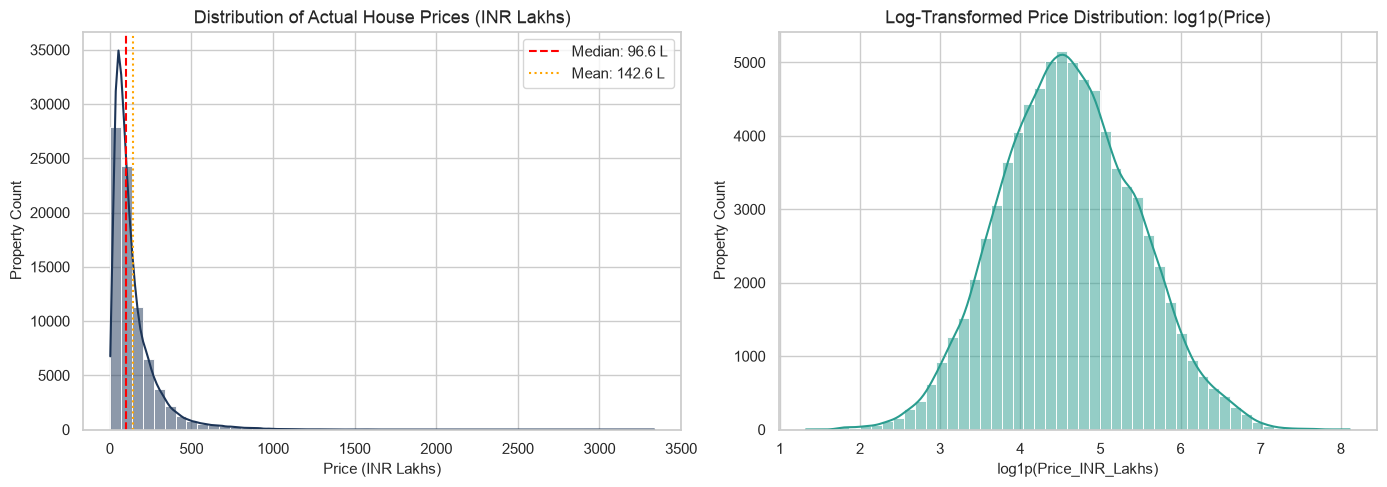

In [5]:
# 1. Price Distribution (Raw & Log-Transformed)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(cleaned_df[TARGET_COL], kde=True, ax=axes[0], color="#1d3557", bins=50)
axes[0].set_title("Distribution of Actual House Prices (INR Lakhs)")
axes[0].set_xlabel("Price (INR Lakhs)")
axes[0].set_ylabel("Property Count")
axes[0].axvline(cleaned_df[TARGET_COL].median(), color="red", linestyle="--", label=f"Median: {cleaned_df[TARGET_COL].median():.1f} L")
axes[0].axvline(cleaned_df[TARGET_COL].mean(), color="orange", linestyle=":", label=f"Mean: {cleaned_df[TARGET_COL].mean():.1f} L")
axes[0].legend()

log_price = np.log1p(cleaned_df[TARGET_COL])
sns.histplot(log_price, kde=True, ax=axes[1], color="#2a9d8f", bins=50)
axes[1].set_title("Log-Transformed Price Distribution: log1p(Price)")
axes[1].set_xlabel("log1p(Price_INR_Lakhs)")
axes[1].set_ylabel("Property Count")

plt.tight_layout()
plt.show()


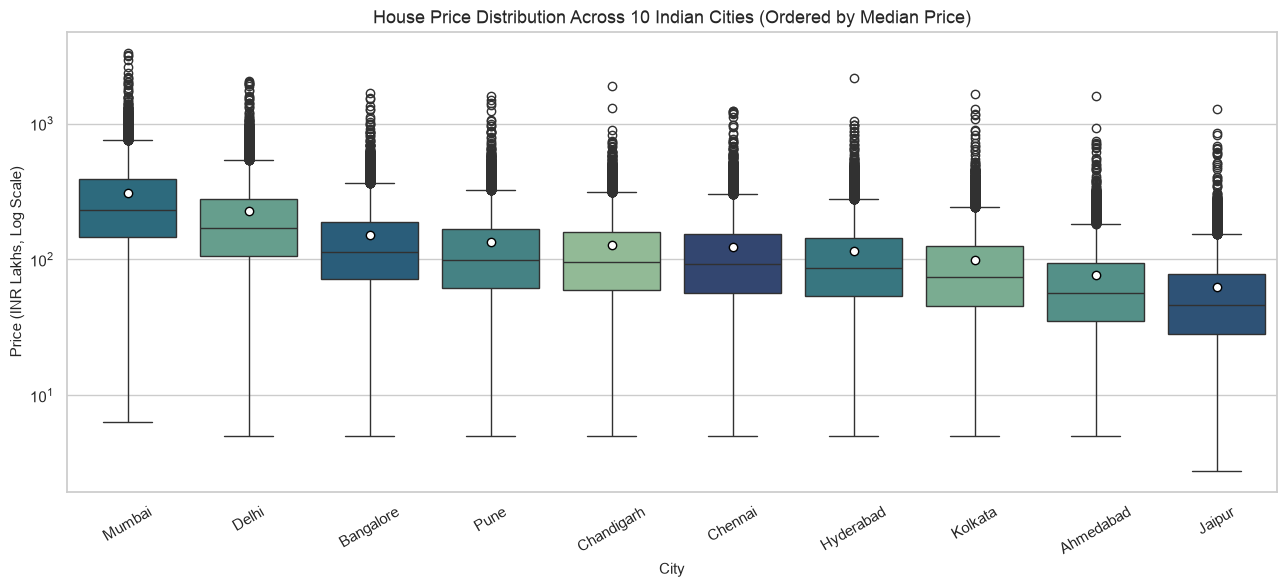

,Count,Median_Lakhs,Mean_Lakhs,Std_Lakhs,Max_Lakhs
City,,,,,
Mumbai,8024,232.542748,308.908895,247.213327,3334.915208
Delhi,8037,170.180000,226.998967,187.536363,2066.850917
Bangalore,8189,113.970000,151.238115,122.263896,1687.654876
Pune,7833,99.560000,133.323447,110.096405,1586.801993
Chandigarh,7873,95.970000,126.942984,99.825442,1902.470366
Chennai,8150,92.820000,123.159102,101.441432,1241.132514
Hyderabad,8060,85.795000,115.107165,95.893570,2148.825381
Kolkata,7850,74.705000,99.395469,85.138552,1664.490058
Ahmedabad,7982,56.730000,76.146560,64.634551,1593.594285


In [6]:
# 2. House Prices Across Indian Cities
fig, ax = plt.subplots(figsize=(13, 6))
city_order = cleaned_df.groupby("City")[TARGET_COL].median().sort_values(ascending=False).index

sns.boxplot(
    data=cleaned_df,
    x="City",
    y=TARGET_COL,
    hue="City",
    order=city_order,
    palette="crest",
    legend=False,
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"},
    ax=ax
)
ax.set_title("House Price Distribution Across 10 Indian Cities (Ordered by Median Price)")
ax.set_xlabel("City")
ax.tick_params(axis="x", rotation=30)
ax.set_yscale("log")
ax.set_ylabel("Price (INR Lakhs, Log Scale)")
plt.tight_layout()
plt.show()

# Display summary statistics table per city
city_summary = cleaned_df.groupby("City")[TARGET_COL].agg(
    Count="count",
    Median_Lakhs="median",
    Mean_Lakhs="mean",
    Std_Lakhs="std",
    Max_Lakhs="max"
).sort_values("Median_Lakhs", ascending=False)
display(city_summary)


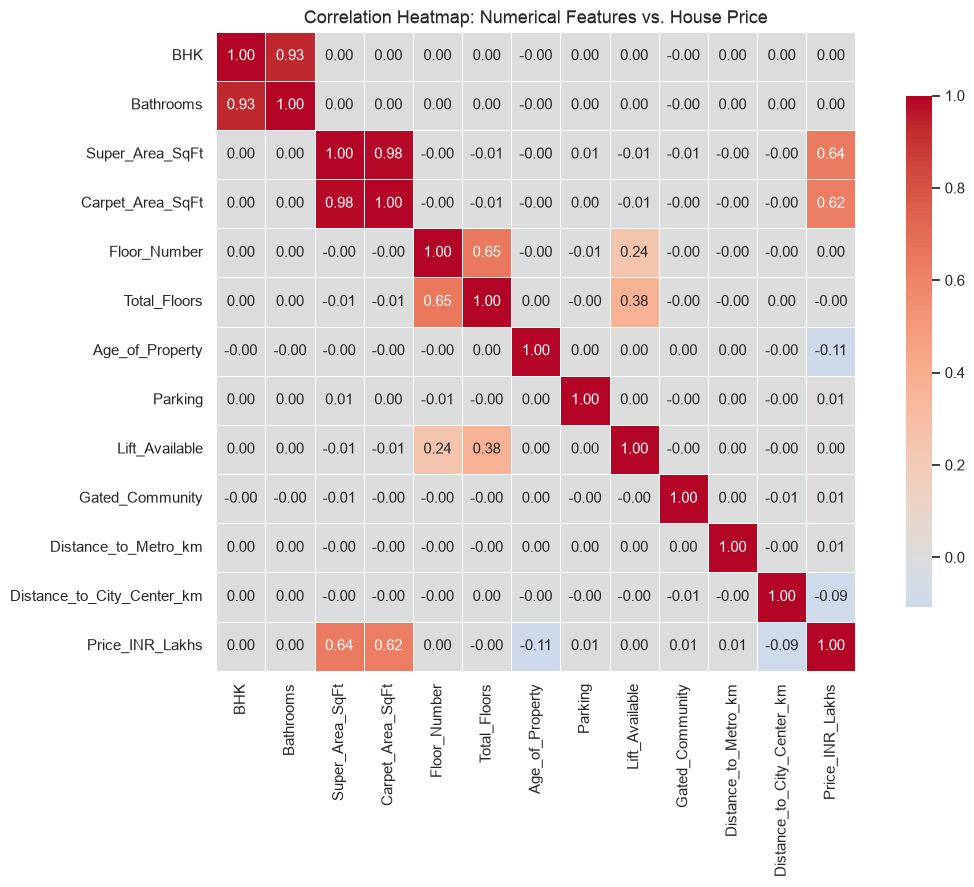

In [7]:
# 3. Correlation Heatmap for Numerical Features
excluded = [ID_COL, TARGET_COL, "original_index"]
num_cols = [c for c in cleaned_df.columns if is_numeric_dtype(cleaned_df[c]) and c not in excluded]
corr_cols = num_cols + [TARGET_COL]

corr_matrix = cleaned_df[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap: Numerical Features vs. House Price")
plt.tight_layout()
plt.show()


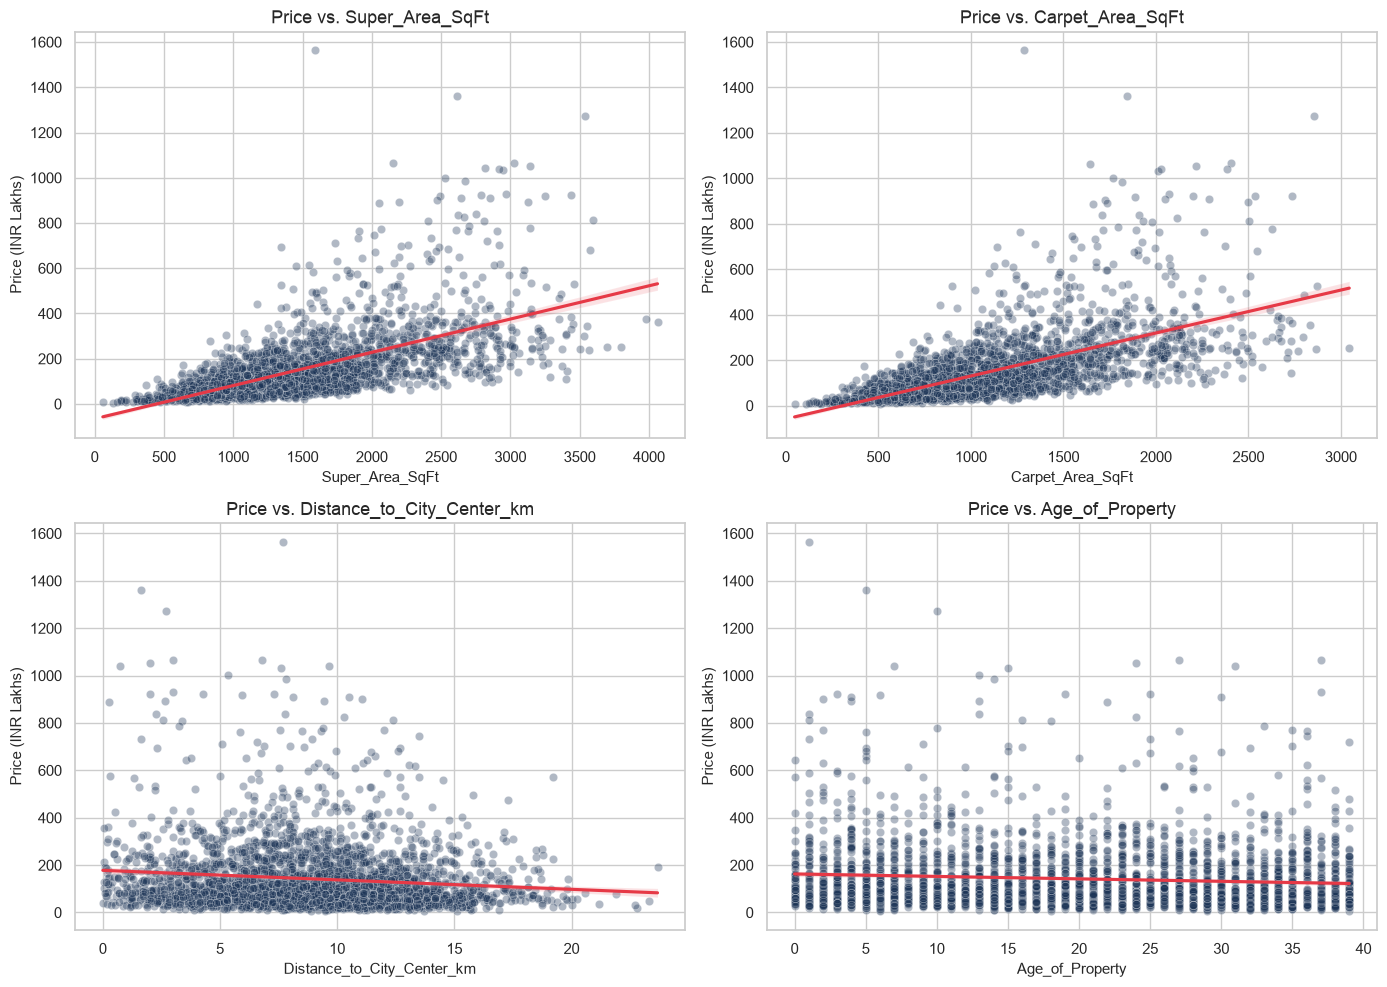

In [8]:
# 4. Scatter Plots of Key Numerical Features vs. Price
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

scatter_feats = ["Super_Area_SqFt", "Carpet_Area_SqFt", "Distance_to_City_Center_km", "Age_of_Property"]
sample_sub = cleaned_df.sample(min(3000, len(cleaned_df)), random_state=42)

for idx, feat in enumerate(scatter_feats):
    sns.scatterplot(data=sample_sub, x=feat, y=TARGET_COL, alpha=0.35, color="#1d3557", ax=axes[idx])
    sns.regplot(data=sample_sub, x=feat, y=TARGET_COL, scatter=False, color="#e63946", ax=axes[idx])
    axes[idx].set_title(f"Price vs. {feat}")
    axes[idx].set_ylabel("Price (INR Lakhs)")

plt.tight_layout()
plt.show()


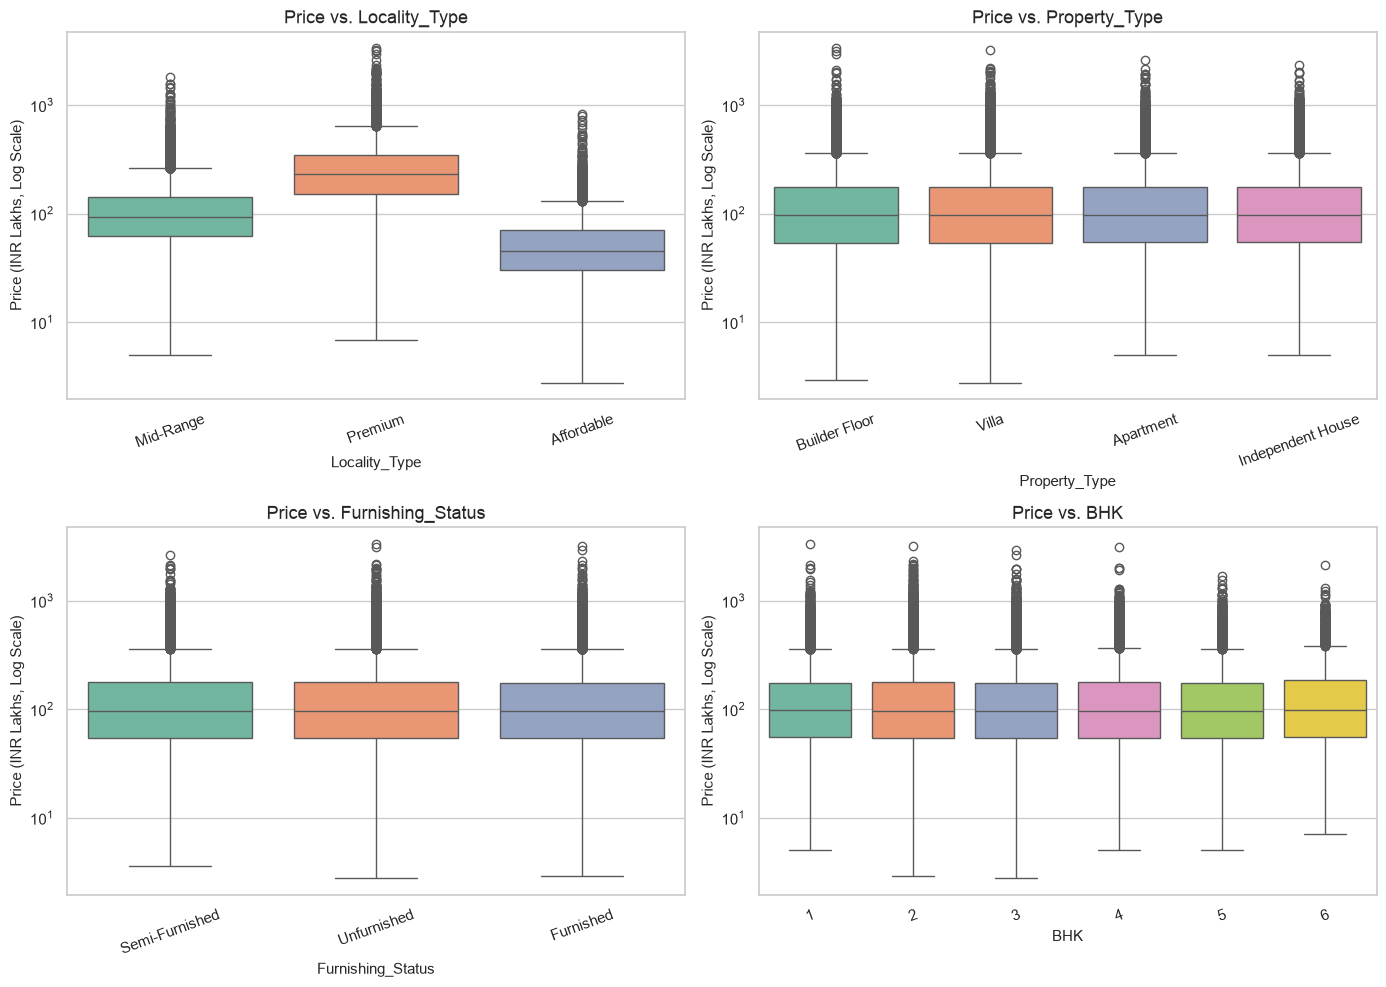

In [9]:
# 5. Boxplots for Locality Type, Property Type, BHK, and Furnishing Status
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

cat_features = ["Locality_Type", "Property_Type", "Furnishing_Status", "BHK"]
for idx, feat in enumerate(cat_features):
    sns.boxplot(data=cleaned_df, x=feat, y=TARGET_COL, hue=feat, legend=False, palette="Set2", ax=axes[idx])
    axes[idx].set_title(f"Price vs. {feat}")
    axes[idx].set_yscale("log")
    axes[idx].set_ylabel("Price (INR Lakhs, Log Scale)")
    axes[idx].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


### Five Key EDA Findings Supported by the Actual Dataset

1. **Substantial Positive Skewness with Real Luxury Representation:**  
   The target `Price_INR_Lakhs` has a median of **96.61 Lakhs** and a mean of **142.61 Lakhs**, with extreme values up to **3,334.92 Lakhs (INR 33.35 Crore)**. Over 211 properties exceed INR 10 Crore. The log-transformed distribution ($\log(1 + 	ext{Price})$) approaches normality, confirming that high-value outliers are genuine luxury real estate assets.

2. **Pronounced Inter-City Valuation Hierarchy:**  
   Indian urban markets exhibit dramatic geographic divergence. **Mumbai** leads all cities with a median price of **232.54 Lakhs** (mean: 308.91 Lakhs), followed by **Delhi** (median: 170.18 Lakhs) and **Bangalore** (median: 113.97 Lakhs). In comparison, **Jaipur** (median: 46.48 Lakhs) and **Ahmedabad** (median: 56.73 Lakhs) have significantly lower median values. A typical home in Mumbai commands over **5.0x** the median price of a home in Jaipur.

3. **Locality Classification is a Major Price Driver:**  
   Categorization by `Locality_Type` exhibits a massive tiering effect:
   - **Premium:** Median = **230.64 Lakhs** (Mean = 284.77 Lakhs)
   - **Mid-Range:** Median = **93.75 Lakhs** (Mean = 115.45 Lakhs)
   - **Affordable:** Median = **45.55 Lakhs** (Mean = 56.52 Lakhs)  
   Homes in Premium localities command over **5.06x** the price of Affordable homes.

4. **Square Footage Dominates Numerical Correlation:**  
   `Super_Area_SqFt` ($r = 0.635$) and `Carpet_Area_SqFt` ($r = 0.624$) show strong linear positive correlation with house price, forming the single most influential continuous physical predictor.

5. **Distance and Age Impose Consistent Market Discounts:**  
   `Age_of_Property` ($r = -0.108$) and `Distance_to_City_Center_km` ($r = -0.091$) consistently discount property valuation. Newer construction and properties located close to urban economic centers enjoy systematic valuation premiums.


## 4. Reproducible Train/Test Split (80:20, `random_state=42`)

All team members must evaluate models on the exact same held-out test records. We export `train_indices.csv` and `test_indices.csv` containing original row indices to guarantee synchronized partitions across the entire HouseWise project.


In [10]:
# 80:20 Reproducible Split
train_df, test_df = train_test_split(
    cleaned_df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

train_indices = pd.DataFrame({
    "original_index": train_df["original_index"],
    ID_COL: train_df[ID_COL]
})

test_indices = pd.DataFrame({
    "original_index": test_df["original_index"],
    ID_COL: test_df[ID_COL]
})

print(f"Training partition size: {len(train_df):,} rows (80.0%)")
print(f"Testing partition size:  {len(test_df):,} rows (20.0%)")

# Save split indices
out_dir = Path("../data/processed") if Path("../data/processed").exists() else Path("data/processed")
out_dir.mkdir(parents=True, exist_ok=True)
train_indices.to_csv(out_dir / "train_indices.csv", index=False)
test_indices.to_csv(out_dir / "test_indices.csv", index=False)
print("Saved train_indices.csv and test_indices.csv successfully.")


Training partition size: 64,000 rows (80.0%)
Testing partition size:  16,000 rows (20.0%)
Saved train_indices.csv and test_indices.csv successfully.


## 5. Scikit-Learn Linear Regression Pipeline Construction

We construct a leakage-free Scikit-Learn `Pipeline`:
- **Numerical Features:** Imputed using **median**, scaled using `StandardScaler`.
- **Categorical Features:** Imputed using **most frequent**, encoded using `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
- **Estimator:** `LinearRegression()`.

All preprocessing transformers are **strictly fitted on the training partition only**.


In [11]:
# Identify features dynamically
excluded_cols = [ID_COL, TARGET_COL, "original_index"]
feature_cols = [c for c in train_df.columns if c not in excluded_cols]

num_features = [c for c in feature_cols if is_numeric_dtype(train_df[c])]
cat_features = [c for c in feature_cols if c not in num_features]
ordered_features = num_features + cat_features

print(f"Numerical Features ({len(num_features)}): {num_features}")
print(f"Categorical Features ({len(cat_features)}): {cat_features}")

# Build preprocessing sub-pipelines
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_features),
        ("cat", cat_pipeline, cat_features)
    ],
    remainder="drop"
)

# Full end-to-end model pipeline
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Fit on training data ONLY
X_train = train_df[ordered_features]
y_train = train_df[TARGET_COL]

linear_pipeline.fit(X_train, y_train)
print("Linear Regression pipeline successfully fitted on training set.")


Numerical Features (12): ['BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km']
Categorical Features (4): ['City', 'Locality_Type', 'Property_Type', 'Furnishing_Status']
Linear Regression pipeline successfully fitted on training set.


## 6. Model Evaluation on Held-Out Test Partition

We evaluate the trained model on the held-out test partition using:
- **MAE (Mean Absolute Error):** Average absolute deviation in Lakhs. Lower is better.
- **RMSE (Root Mean Squared Error):** Square root of mean squared error, penalizing large pricing mistakes. Lower is better.
- **$R^2$ (Coefficient of Determination):** Proportion of price variance explained. Higher is better (up to 1.0).


In [12]:
# Predict on held-out test data
X_test = test_df[ordered_features]
y_test = test_df[TARGET_COL]

y_pred_test = linear_pipeline.predict(X_test)
y_pred_train = linear_pipeline.predict(X_train)

# Calculate metrics
test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_r2 = r2_score(y_test, y_pred_test)

train_mae = mean_absolute_error(y_train, y_pred_train)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
train_r2 = r2_score(y_train, y_pred_train)

metrics_summary = pd.DataFrame([{
    "Dataset Partition": "Held-Out Test (20%)",
    "MAE (INR Lakhs)": round(test_mae, 4),
    "RMSE (INR Lakhs)": round(test_rmse, 4),
    "R² Score": round(test_r2, 4),
    "Sample Count": len(X_test)
}, {
    "Dataset Partition": "Training Set (80%)",
    "MAE (INR Lakhs)": round(train_mae, 4),
    "RMSE (INR Lakhs)": round(train_rmse, 4),
    "R² Score": round(train_r2, 4),
    "Sample Count": len(X_train)
}])

display(metrics_summary)


,Dataset Partition,MAE (INR Lakhs),RMSE (INR Lakhs),R² Score,Sample Count
0,Held-Out Test (20%),47.9403,86.0255,0.6657,16000
1,Training Set (80%),47.7235,84.2302,0.6710,64000


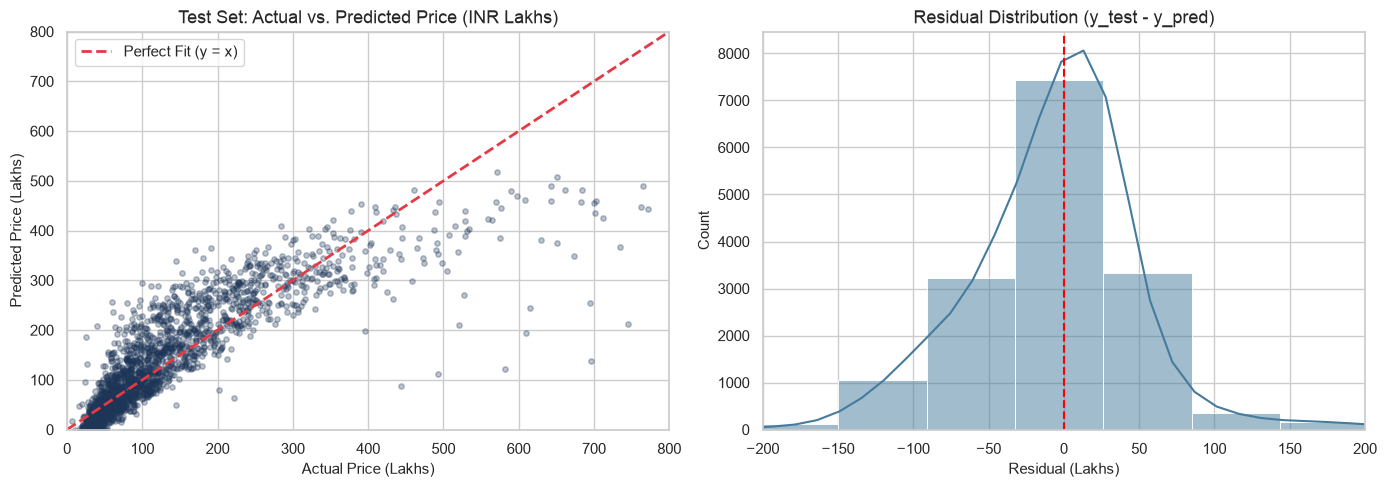

In [13]:
# Diagnostic Plots: Actual vs Predicted & Residuals
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test[:2000], y_pred_test[:2000], alpha=0.3, color="#1d3557", s=15)
axes[0].plot([0, 800], [0, 800], color="#e63946", linestyle="--", lw=2, label="Perfect Fit (y = x)")
axes[0].set_title("Test Set: Actual vs. Predicted Price (INR Lakhs)")
axes[0].set_xlabel("Actual Price (Lakhs)")
axes[0].set_ylabel("Predicted Price (Lakhs)")
axes[0].set_xlim(0, 800)
axes[0].set_ylim(0, 800)
axes[0].legend()

# Residual distribution
residuals = y_test - y_pred_test
sns.histplot(residuals, kde=True, ax=axes[1], color="#457b9d", bins=50)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Residual Distribution (y_test - y_pred)")
axes[1].set_xlabel("Residual (Lakhs)")
axes[1].set_ylabel("Count")
axes[1].set_xlim(-200, 200)

plt.tight_layout()
plt.show()


## 7. Model Artifact Export & Feature Schema

We save:
- `models/linear_regression_model.joblib`: Complete fitted Scikit-Learn pipeline ready for FastAPI loading.
- `reports/feature_schema.json`: Complete input feature contract for Person 2 (FastAPI) and Person 3 (React UI).


In [14]:
# Export fitted model pipeline
models_dir = Path("../models") if Path("../models").exists() else Path("models")
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "linear_regression_model.joblib"

joblib.dump(linear_pipeline, model_path)
print(f"Fitted model saved to: {model_path.resolve()}")

# Export feature schema
reports_dir = Path("../reports") if Path("../reports").exists() else Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

schema_payload = {
    "project_name": "HouseWise",
    "author": "Person 1 (Data Preprocessing, EDA & Linear Regression)",
    "target": {
        "column_name": TARGET_COL,
        "unit": "INR Lakhs (1 Lakh = 100,000 INR)",
        "description": "Final property sale price in Lakhs"
    },
    "features": {
        "all_features_ordered": ordered_features,
        "numerical_features": num_features,
        "categorical_features": cat_features,
        "excluded_columns": excluded_cols,
        "total_feature_count": len(ordered_features)
    },
    "split_configuration": {
        "train_ratio": 0.80,
        "test_ratio": 0.20,
        "random_state": 42,
        "train_row_count": len(train_df),
        "total_cleaned_rows": len(cleaned_df)
    },
    "preprocessing_pipeline": {
        "numerical": "SimpleImputer(strategy='median') -> StandardScaler()",
        "categorical": "SimpleImputer(strategy='most_frequent') -> OneHotEncoder(handle_unknown='ignore', sparse_output=False)",
        "estimator": "LinearRegression()"
    }
}

with open(reports_dir / "feature_schema.json", "w", encoding="utf-8") as f:
    json.dump(schema_payload, f, indent=2)

print(f"Feature schema exported to: {(reports_dir / 'feature_schema.json').resolve()}")


Fitted model saved to: /Users/shrutiahir/Desktop/House Price Prediction/models/linear_regression_model.joblib
Feature schema exported to: /Users/shrutiahir/Desktop/House Price Prediction/reports/feature_schema.json


## 8. Automated Pipeline Reload & Verification Test

We reload the exported pipeline artifact from disk and run a single-row prediction simulating the FastAPI request/response lifecycle.


In [15]:
# Reload saved pipeline from disk
reloaded_pipeline = joblib.load(model_path)

# Mock incoming FastAPI payload (single property)
mock_request = {
    "BHK": 3,
    "Bathrooms": 3,
    "Super_Area_SqFt": 1850.0,
    "Carpet_Area_SqFt": 1420.0,
    "Floor_Number": 8,
    "Total_Floors": 20,
    "Age_of_Property": 5,
    "Parking": 1,
    "Lift_Available": 1,
    "Gated_Community": 1,
    "Distance_to_Metro_km": 1.5,
    "Distance_to_City_Center_km": 6.2,
    "City": "Bangalore",
    "Locality_Type": "Premium",
    "Property_Type": "Apartment",
    "Furnishing_Status": "Furnished"
}

# Construct DataFrame matching schema
input_df = pd.DataFrame([mock_request])[ordered_features]
prediction = reloaded_pipeline.predict(input_df)

assert len(prediction) == 1, "Expected 1 prediction output"
assert np.isfinite(prediction[0]), "Prediction is not finite!"
print("✓ Verification Test Passed!")
print(f"  Input Property: 3 BHK Premium Apartment in Bangalore (1850 sq ft)")
print(f"  Predicted Valuation: {prediction[0]:.2f} Lakhs (INR {prediction[0]*100000:,.0f})")


✓ Verification Test Passed!
  Input Property: 3 BHK Premium Apartment in Bangalore (1850 sq ft)
  Predicted Valuation: 284.97 Lakhs (INR 28,496,811)


## 9. Team Integration Guide (Person 2 & Person 3 Handoff)

### Integration Instructions for Person 2 (FastAPI Backend):
```python
import joblib
import pandas as pd

# 1. Load pipeline at application startup
pipeline = joblib.load("models/linear_regression_model.joblib")

# 2. Convert incoming Pydantic request to DataFrame
# (No manual scaling or one-hot encoding needed; pipeline handles everything internally)
features_df = pd.DataFrame([request_data.dict()])

# 3. Predict price directly
predicted_price_lakhs = float(pipeline.predict(features_df)[0])
```

### Integration Instructions for Person 3 (React Frontend):
- Refer to `reports/feature_schema.json` for all dropdown options (`City`, `Locality_Type`, `Property_Type`, `Furnishing_Status`) and numeric input fields.
- Send JSON payload containing the ordered feature keys. The response represents property price in **INR Lakhs**.
